# Assignment № 3 — Task 2: Automatic Text Summarization


## 1. Install and import libraries

In [1]:
%pip -q install pandas numpy scikit-learn nltk matplotlib rouge-score transformers torch sentencepiece


Note: you may need to restart the kernel to use updated packages.


In [9]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from nltk.tokenize import sent_tokenize

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

DATA_PATH = "data/bbc_summarization_dataset.csv"


## 2. Load and inspect the dataset

If the CSV is not in the same folder as this notebook, change `DATA_PATH` to its location.


In [10]:
df = pd.read_csv(DATA_PATH)
required_columns = {"document_id", "title", "source", "word_count", "text"}
missing = required_columns - set(df.columns)
if missing:
    raise ValueError(f"CSV is missing required columns: {missing}")

df["document_id"] = df["document_id"].astype(str)
reference_rows = df[df["document_id"].str.lower().isin(["reference_summary", "reference", "summary"])]
documents = df[~df.index.isin(reference_rows.index)].copy()

# Keep the five source documents in their original order.
documents = documents.head(5).reset_index(drop=True)
if len(documents) != 5:
    raise ValueError(f"Expected 5 source documents, found {len(documents)}.")

if len(reference_rows):
    reference_summary = str(reference_rows.iloc[0]["text"]).strip()
else:
    reference_summary = ""

documents["actual_word_count"] = documents["text"].fillna("").apply(lambda x: len(str(x).split()))
display(documents[["document_id", "title", "source", "word_count", "actual_word_count"]])
print("Number of source documents:", len(documents))
print("Reference summary available:", bool(reference_summary))
print("Reference summary words:", len(reference_summary.split()) if reference_summary else 0)


,document_id,title,source,word_count,actual_word_count
0,doc1,Tech CEOs suddenly love blaming AI for mass jo...,BBC News Business,183,183
1,doc2,Financial analysts warn of dangerous AI invest...,BBC News Economy,159,159
2,doc3,AI data centers surge global electricity demand,BBC News Technology,165,165
3,doc4,Cybersecurity threat landscape shifts as hacke...,BBC News CyberSecurity,152,152
4,doc5,Global leaders debate unified AI regulatory fr...,BBC News World,151,151


Number of source documents: 5
Reference summary available: True
Reference summary words: 112


Missing text values: 0
Duplicate texts: 0
Word counts (actual):


,title,actual_word_count
0,Tech CEOs suddenly love blaming AI for mass jo...,183
1,Financial analysts warn of dangerous AI invest...,159
2,AI data centers surge global electricity demand,165
3,Cybersecurity threat landscape shifts as hacke...,152
4,Global leaders debate unified AI regulatory fr...,151


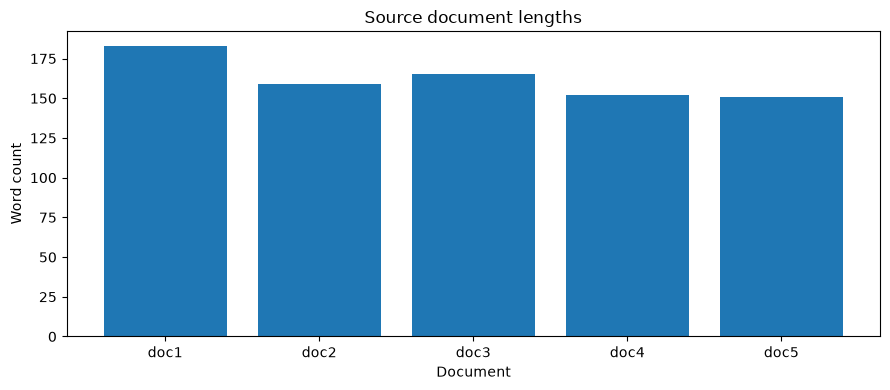

In [11]:
# Check for empty texts and duplicate source documents
print("Missing text values:", documents["text"].isna().sum())
print("Duplicate texts:", documents["text"].duplicated().sum())
print("Word counts (actual):")
display(documents[["title", "actual_word_count"]])

plt.figure(figsize=(9, 4))
plt.bar(documents["document_id"], documents["actual_word_count"])
plt.title("Source document lengths")
plt.xlabel("Document")
plt.ylabel("Word count")
plt.tight_layout()
plt.show()


## 3. Preprocess and split documents into sentences

Sentence tokenization is used to preserve original sentence wording for extractive summaries. We normalize whitespace, but keep a separate original sentence list so the final extractive summary uses the original text. NLTK may need to download its tokenizer data on first use.


In [12]:
import nltk
try:
    nltk.data.find("tokenizers/punkt")
except LookupError:
    nltk.download("punkt", quiet=True)
try:
    nltk.data.find("tokenizers/punkt_tab")
except LookupError:
    nltk.download("punkt_tab", quiet=True)

def clean_whitespace(text):
    return re.sub(r"\\s+", " ", str(text)).strip()

documents["clean_text"] = documents["text"].fillna("").apply(clean_whitespace)

def split_sentences(text):
    text = clean_whitespace(text)
    try:
        sentences = sent_tokenize(text, language="english")
    except LookupError:
        nltk.download("punkt", quiet=True)
        nltk.download("punkt_tab", quiet=True)
        sentences = sent_tokenize(text, language="english")
    return [s.strip() for s in sentences if s.strip()]

documents["sentences"] = documents["clean_text"].apply(split_sentences)
for _, row in documents.iterrows():
    print(f"{row['document_id']} — {row['title']}: {len(row['sentences'])} sentences")


doc1 — Tech CEOs suddenly love blaming AI for mass job cuts: 8 sentences
doc2 — Financial analysts warn of dangerous AI investment bubble: 7 sentences
doc3 — AI data centers surge global electricity demand: 8 sentences
doc4 — Cybersecurity threat landscape shifts as hackers weaponize AI: 7 sentences
doc5 — Global leaders debate unified AI regulatory frameworks: 7 sentences


## 4. Extractive summarization with TF-IDF

The approach represents sentences using TF-IDF and calculates sentence importance from the average TF-IDF weight of its terms. For each document, it selects the three highest-scoring sentences, then restores their original order to make the summary easier to read.

This is a simple, explainable baseline. TF-IDF sentence scoring does not fully understand meaning, and repeated terms can influence its ranking.


In [13]:
def sentence_tfidf_scores(sentences):
    if not sentences:
        return np.array([])
    # Word-level TF-IDF. Sublinear TF reduces the influence of repeated terms.
    vectorizer = TfidfVectorizer(stop_words="english", sublinear_tf=True)
    try:
        matrix = vectorizer.fit_transform(sentences)
    except ValueError:  # e.g., all sentences contain only stop words
        return np.zeros(len(sentences))
    # Mean TF-IDF weight per sentence; sparse matrices are converted safely.
    return np.asarray(matrix.mean(axis=1)).ravel()

def top_sentence_indices(sentences, n=3):
    scores = sentence_tfidf_scores(sentences)
    if len(scores) == 0:
        return [], scores
    n = min(n, len(sentences))
    selected = np.argsort(scores)[::-1][:n]
    # Restore source order for readability.
    return sorted(selected.tolist()), scores

per_document_results = []
for _, row in documents.iterrows():
    sentences = row["sentences"]
    selected_indices, scores = top_sentence_indices(sentences, n=3)
    selected_sentences = [sentences[i] for i in selected_indices]
    per_document_results.append({
        "document_id": row["document_id"],
        "title": row["title"],
        "selected_indices": selected_indices,
        "selected_sentences": selected_sentences,
        "sentence_scores": scores
    })

for result in per_document_results:
    print("\\n" + "="*90)
    print(result["document_id"], "—", result["title"])
    for number, sentence in enumerate(result["selected_sentences"], start=1):
        print(f"{number}. {sentence}")


\n==========================================================================================
doc1 — Tech CEOs suddenly love blaming AI for mass job cuts
1. Industry leaders argue that traditional software engineering and administrative roles are being rendered obsolete by advanced machine learning models capable of writing code and managing databases at a fraction of the cost.
2. Activists suggest that companies are merely using AI as a convenient corporate excuse to slash headcount, reduce operational expenses, and boost quarterly profit margins to satisfy demanding Wall Street investors.
3. The debate highlights a critical tension between corporate efficiency and social responsibility in the modern digital age, as society struggles to adapt to the accelerating pace of technological disruption.
\n==========================================================================================
doc2 — Financial analysts warn of dangerous AI investment bubble
1. Major venture capital firms and 

## 5. Combined extractive summary: six sentences from the 15 candidates

The assignment asks for six sentences selected from the 15 sentences extracted above. To rank these candidates consistently, this cell calculates TF-IDF importance over the full set of candidate sentences. The final six are then presented in the order in which their source documents appear, and in their original sentence order within each document.

This approach is deterministic and uses `RANDOM_SEED = 42` for reproducibility, although TF-IDF ranking itself does not require randomness.


In [14]:
candidate_records = []
for doc_order, result in enumerate(per_document_results):
    for sent_order, sentence in zip(result["selected_indices"], result["selected_sentences"]):
        candidate_records.append({
            "document_id": result["document_id"],
            "title": result["title"],
            "doc_order": doc_order,
            "sentence_index": sent_order,
            "sentence": sentence
        })

candidates = pd.DataFrame(candidate_records)
assert len(candidates) == 15, f"Expected 15 candidates, got {len(candidates)}"

candidate_scores = sentence_tfidf_scores(candidates["sentence"].tolist())
candidates["score"] = candidate_scores
top6 = candidates.nlargest(6, "score").sort_values(["doc_order", "sentence_index"])

extractive_summary = " ".join(top6["sentence"].tolist())
print("Combined extractive summary (6 sentences):\\n")
print(extractive_summary)
print("\\nWord count:", len(extractive_summary.split()))
display(candidates.sort_values("score", ascending=False)[["document_id", "score", "sentence"]])


Combined extractive summary (6 sentences):\n
Industry leaders argue that traditional software engineering and administrative roles are being rendered obsolete by advanced machine learning models capable of writing code and managing databases at a fraction of the cost. Activists suggest that companies are merely using AI as a convenient corporate excuse to slash headcount, reduce operational expenses, and boost quarterly profit margins to satisfy demanding Wall Street investors. Major venture capital firms and retail investors have poured billions of dollars into AI startups, driving stock valuations of semiconductor manufacturers and software companies to historic heights. Economists note that while generative AI technology possesses genuine transformative potential, many current applications fail to generate sustainable revenue streams or justify their massive computational costs. This massive electricity consumption has led to a unexpected revival of fossil-fuel reliance, with severa

,document_id,score,sentence
1,doc1,0.019071,Activists suggest that companies are merely us...
13,doc5,0.018316,The European Union has implemented strict risk...
0,doc1,0.018300,Industry leaders argue that traditional softwa...
7,doc3,0.017862,This massive electricity consumption has led t...
4,doc2,0.017788,Economists note that while generative AI techn...
3,doc2,0.017766,Major venture capital firms and retail investo...
5,doc2,0.017395,If tech enterprises fail to deliver substantia...
6,doc3,0.017311,Modern data centers packed with high-performan...
2,doc1,0.016930,The debate highlights a critical tension betwe...
9,doc4,0.016843,AI-driven systems can analyze security network...


## 6. Abstractive summarization with a pretrained Transformer (BART)

We use `facebook/bart-large-cnn`, a pretrained model designed for summarization. Because the five documents together may exceed a model's input length, each document is summarized separately and the resulting short summaries are summarized again (hierarchical summarization). Generation settings are fixed for reproducibility.

In [16]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

MODEL_NAME = "facebook/bart-large-cnn"
GENERATION_SETTINGS = {
    "max_length": 90,
    "min_length": 35,
    "do_sample": False,
    "num_beams": 4,
}

abstractive_summary = None

try:
    print("Loading tokenizer and model...")
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME)
    
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    model.eval()

    document_summaries = []
    for _, row in documents.iterrows():
        # Токенизируем текст с ограничением длины (truncation)
        inputs = tokenizer(
            row["clean_text"], 
            return_tensors="pt", 
            truncation=True, 
            max_length=1024
        ).to(device)
        
        with torch.inference_mode():
            outputs = model.generate(**inputs, **GENERATION_SETTINGS)
            
        summary_text = tokenizer.decode(outputs[0], skip_special_tokens=True).strip()
        document_summaries.append(summary_text)

    intermediate_text = " ".join(document_summaries)
    
    # Настройки для финальной суммаризации (100–150 слов)
    final_settings = {
        "max_length": 160,
        "min_length": 100,
        "do_sample": False,
        "num_beams": 4,
    }
    
    final_inputs = tokenizer(
        intermediate_text, 
        return_tensors="pt", 
        truncation=True, 
        max_length=1024
    ).to(device)
    
    with torch.inference_mode():
        final_outputs = model.generate(**final_inputs, **final_settings)
        
    abstractive_summary = tokenizer.decode(final_outputs[0], skip_special_tokens=True).strip()
    
    print("Abstractive summary:\n")
    print(abstractive_summary)
    print("\nWord count:", len(abstractive_summary.split()))
    
except Exception as e:
    print("Transformer model could not be loaded or executed in this environment.")
    print("Error:", repr(e))
    print("Check internet access, installed packages, and available RAM, then rerun this cell.")

Loading tokenizer and model...


C:\Users\Daniyar\AppData\Local\Programs\Python\Python313\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Daniyar\.cache\huggingface\hub. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 
Loading weights: 100%|████████

Abstractive summary:

Tech CEOs are increasingly pointing to automation and AI integration as the primary reason for corporate restructuring and mass job cuts. Experts warn that if companies continue to prioritize rapid automation over workforce retraining, it could lead to severe long-term economic instability. Cybersecurity specialists warn that the weaponization of artificial intelligence is fundamentally altering the global threat landscape. Legal experts argue that without standardized global guidelines, it will be impossible to prevent malicious actors from exploiting regulatory loopholes. The rapid deployment of autonomous technologies has created a complex web of legal and ethical challenges.

Word count: 94


## 7. Quantitative evaluation with ROUGE-1, ROUGE-2 and ROUGE-L

ROUGE compares n-gram overlap between a generated summary and a reference summary. We compare the six-sentence extractive summary and the Transformer summary against the same human-written reference summary included in the CSV.

ROUGE measures lexical overlap, not factual correctness. A higher score does not automatically mean that a summary is more accurate or more readable.


In [17]:
from rouge_score import rouge_scorer

if not reference_summary:
    raise ValueError("No reference summary was found in the CSV. Add a human-written reference summary before computing ROUGE.")

scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)

def rouge_row(name, prediction, reference):
    scores = scorer.score(reference, prediction)
    return {
        "Method": name,
        "ROUGE-1 F1": scores["rouge1"].fmeasure,
        "ROUGE-2 F1": scores["rouge2"].fmeasure,
        "ROUGE-L F1": scores["rougeL"].fmeasure
    }

evaluation_rows = [rouge_row("Extractive TF-IDF (6 sentences)", extractive_summary, reference_summary)]
if abstractive_summary:
    evaluation_rows.append(rouge_row("Abstractive BART", abstractive_summary, reference_summary))
else:
    print("Abstractive summary unavailable, so its ROUGE scores are not reported.")

results = pd.DataFrame(evaluation_rows)
display(results.style.format({
    "ROUGE-1 F1": "{:.4f}",
    "ROUGE-2 F1": "{:.4f}",
    "ROUGE-L F1": "{:.4f}"
}))


,Method,ROUGE-1 F1,ROUGE-2 F1,ROUGE-L F1
0,Extractive TF-IDF (6 sentences),0.2215,0.0070,0.1038
1,Abstractive BART,0.3732,0.0580,0.1722


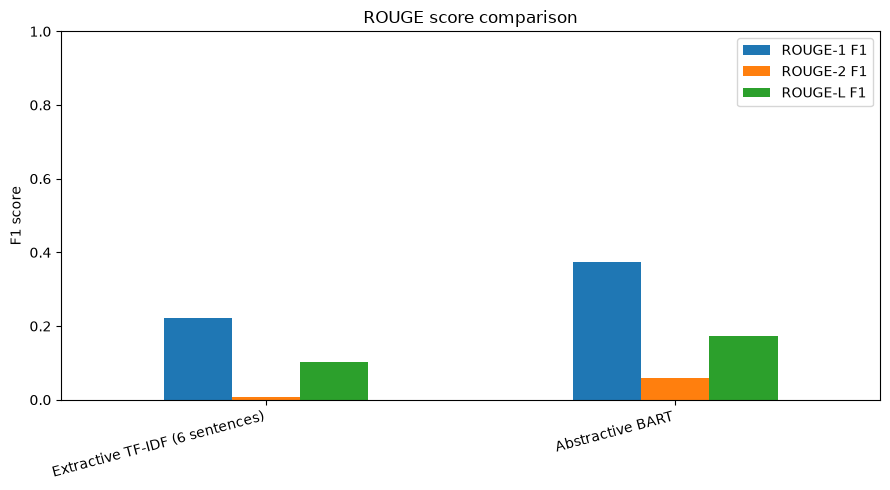

In [18]:
if not results.empty:
    results_plot = results.set_index("Method")
    results_plot.plot(kind="bar", figsize=(9, 5), ylim=(0, 1))
    plt.title("ROUGE score comparison")
    plt.ylabel("F1 score")
    plt.xlabel("")
    plt.xticks(rotation=15, ha="right")
    plt.legend(loc="best")
    plt.tight_layout()
    plt.show()


## 8. Qualitative analysis

Use the checklist below to compare the summaries. The text in the output cells is generated from the actual summaries, but the final interpretation should be checked by the student against the source documents.


In [19]:
print("REFERENCE SUMMARY\\n", reference_summary)
print("\\nEXTRACTIVE SUMMARY\\n", extractive_summary)
print("\\nABSTRACTIVE SUMMARY\\n", abstractive_summary if abstractive_summary else "[Not generated — Transformer unavailable]")


REFERENCE SUMMARY\n The rapid advancement of artificial intelligence is reshaping society while introducing severe economic, environmental, and security challenges. Tech corporations are increasingly attributing mass layoffs to AI automation, raising concerns about workforce stability. Simultaneously, financial experts warn of an investment bubble driven by inflated valuations that mirror the dot-com crash. Beyond economic risks, the immense power requirements of AI data centers threaten global climate initiatives by increasing reliance on fossil fuels. In the digital realm, AI-driven cyber threats are accelerating a global cyber arms race, making automated defensive systems vital. To mitigate these multifaceted risks, international policymakers are struggling to create unified regulatory frameworks, balancing technological innovation against ethical governance and human rights.
\nEXTRACTIVE SUMMARY\n Industry leaders argue that traditional software engineering and administrative roles

### Qualitative comparison checklist

Fill in these observations after reading the summaries:

| Criterion | Extractive TF-IDF | Abstractive BART |
|---|---|---|
| Coverage of all five documents | Does the six-sentence summary represent all key themes? | Does the generated summary cover all key themes? |
| Coherence and readability | Are the selected sentences connected naturally? | Does the model combine ideas into fluent prose? |
| Redundancy | Are similar points repeated? | Are ideas repeated or compressed effectively? |
| Factual consistency | Are statements copied faithfully from the source? | Does the model add, alter, or omit any facts? |
| Grammar | Original grammar is preserved | Generated grammar may be fluent, but must be checked |

**Expected methodological differences (not experimental results):**
1. Extractive summarization selects sentences from the source and preserves their wording.
2. Abstractive summarization generates new wording and can produce a more compact narrative.
3. Extractive summaries are usually easier to trace to the source, while abstractive summaries may introduce hallucinations or omit details.


## 9. Error and factual-consistency analysis

The assignment asks for at least one example where the abstractive model changes, omits, or adds information. Compare each claim in the BART summary with the five source documents. Record only examples you can verify.

| Generated claim or omission | Evidence in source document | Type of issue | Possible reason |
|---|---|---|---|
| Fill after reviewing the generated summary | Document ID and source sentence | Added / changed / omitted | Compression, ambiguity, model limitation |

Do not invent an error example if the model output does not support it. If BART did not run, state that factual analysis of its output could not be performed.


## 10. Conclusion

Complete the conclusion after running the notebook and reviewing the outputs:

- The extractive method used TF-IDF sentence scores to select three sentences from each document and six sentences from the 15 candidates.
- The abstractive method used a pretrained BART model with hierarchical summarization, if the model loaded successfully.
- Compare ROUGE-1, ROUGE-2 and ROUGE-L using the values printed in the evaluation table; do not assume one method is better before observing the results.
- Discuss qualitative coverage, readability, redundancy, factual consistency and grammar.
- Limitation: the supplied source documents are shorter than the assignment's recommended minimum of 250 words each, and ROUGE scores depend on the quality and wording of the single reference summary.

**Reproducibility:** random seed = 42; extractive method = sentence-level TF-IDF; abstractive model = `facebook/bart-large-cnn`; deterministic generation = `do_sample=False`, `num_beams=4`. Record your Python and library versions if requested.
